In [1]:
from google.colab import files
uploaded = files.upload()

Saving machine_failure_dataset.csv to machine_failure_dataset.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Imported")

Imported


In [3]:
df=pd.read_csv("machine_failure_dataset.csv")
print(df)

    Record_ID Machine_Type Operating_Mode Lubrication_Type  Temperature_C  \
0    REC_1000       Type_A            Eco        Synthetic          59.00   
1    REC_1001       Type_C       Standard          Mineral          89.15   
2    REC_1002       Type_B      High_Load          Mineral          79.89   
3    REC_1003       Type_B       Standard        Synthetic          71.22   
4    REC_1004       Type_A            Eco        Synthetic          83.28   
..        ...          ...            ...              ...            ...   
245  REC_1245       Type_C       Standard        Synthetic            NaN   
246  REC_1246       Type_B       Standard          Mineral          70.88   
247  REC_1247       Type_C            Eco          Mineral          92.71   
248  REC_1248       Type_C      High_Load        Synthetic          94.17   
249  REC_1249       Type_C      High_Load        Synthetic          69.99   

     Vibration_mm_s  Pressure_kPa     RPM  Operating_Hours Failure_Status  

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Record_ID         250 non-null    object 
 1   Machine_Type      245 non-null    object 
 2   Operating_Mode    250 non-null    object 
 3   Lubrication_Type  250 non-null    object 
 4   Temperature_C     243 non-null    float64
 5   Vibration_mm_s    250 non-null    float64
 6   Pressure_kPa      244 non-null    float64
 7   RPM               250 non-null    float64
 8   Operating_Hours   250 non-null    float64
 9   Failure_Status    250 non-null    object 
dtypes: float64(5), object(5)
memory usage: 19.7+ KB


In [5]:
df.columns

Index(['Record_ID', 'Machine_Type', 'Operating_Mode', 'Lubrication_Type',
       'Temperature_C', 'Vibration_mm_s', 'Pressure_kPa', 'RPM',
       'Operating_Hours', 'Failure_Status'],
      dtype='object')

In [6]:
df.describe()

,Temperature_C,Vibration_mm_s,Pressure_kPa,RPM,Operating_Hours
count,243.000000,250.000000,244.000000,250.000000,250.000000
mean,76.406708,2.361796,100.956230,3135.530000,2585.415200
std,11.465964,1.852458,14.377404,377.697592,1401.235078
min,44.990000,0.512000,59.450000,2115.400000,161.800000
25%,69.465000,0.970500,91.015000,2872.025000,1359.550000
50%,76.330000,1.849500,100.895000,3127.800000,2611.650000
75%,83.925000,3.152000,110.207500,3378.100000,3843.525000
max,106.270000,11.033000,136.120000,4088.600000,4991.900000


In [7]:
df.skew(numeric_only=True)

,0
Temperature_C,0.092191
Vibration_mm_s,1.745021
Pressure_kPa,-0.048032
RPM,0.008918
Operating_Hours,-0.036660


In [8]:
df.corr(numeric_only=True)

,Temperature_C,Vibration_mm_s,Pressure_kPa,RPM,Operating_Hours
Temperature_C,1.000000,-0.059225,-0.029364,0.023679,0.026790
Vibration_mm_s,-0.059225,1.000000,-0.007294,-0.041330,-0.016952
Pressure_kPa,-0.029364,-0.007294,1.000000,0.067449,-0.004951
RPM,0.023679,-0.041330,0.067449,1.000000,0.023772
Operating_Hours,0.026790,-0.016952,-0.004951,0.023772,1.000000


In [9]:
df.isnull().sum()

,0
Record_ID,0
Machine_Type,5
Operating_Mode,0
Lubrication_Type,0
Temperature_C,7
Vibration_mm_s,0
Pressure_kPa,6
RPM,0
Operating_Hours,0
Failure_Status,0


In [10]:
df=df.drop(columns=["Record_ID"])

In [11]:
print(df)

    Machine_Type Operating_Mode Lubrication_Type  Temperature_C  \
0         Type_A            Eco        Synthetic          59.00   
1         Type_C       Standard          Mineral          89.15   
2         Type_B      High_Load          Mineral          79.89   
3         Type_B       Standard        Synthetic          71.22   
4         Type_A            Eco        Synthetic          83.28   
..           ...            ...              ...            ...   
245       Type_C       Standard        Synthetic            NaN   
246       Type_B       Standard          Mineral          70.88   
247       Type_C            Eco          Mineral          92.71   
248       Type_C      High_Load        Synthetic          94.17   
249       Type_C      High_Load        Synthetic          69.99   

     Vibration_mm_s  Pressure_kPa     RPM  Operating_Hours Failure_Status  
0             0.991        124.30  3164.4            534.1             No  
1             0.711        102.77  2562.8  

In [12]:
X=df.drop(columns=["Failure_Status"])
y=df["Failure_Status"]

In [13]:
print(X.shape)

(250, 8)


In [14]:
print(y.shape)

(250,)


In [15]:
df["Failure_Status"].value_counts()

,count
Failure_Status,
Yes,146
No,104


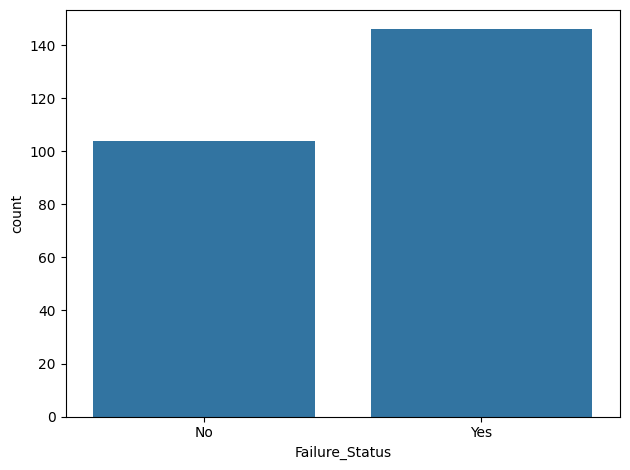

In [16]:
sns.countplot(data=df,x='Failure_Status')
plt.tight_layout()
plt.show()

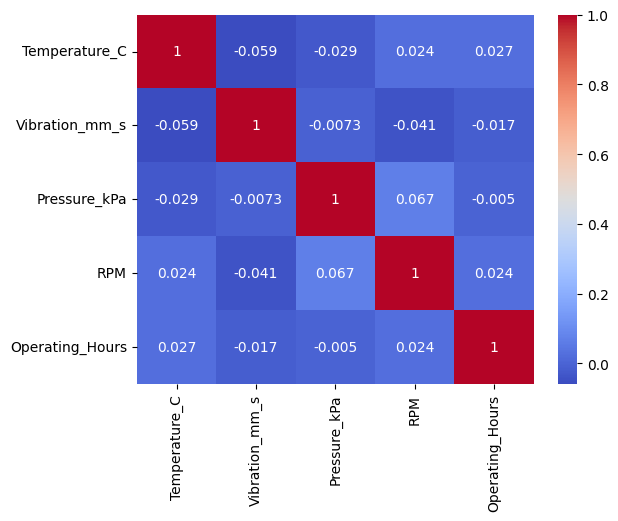

In [18]:
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm")
plt.show()

In [22]:
for col in df.select_dtypes(include=np.number).columns:
  Q1=df[col].quantile(0.25)
  Q3=df[col].quantile(0.75)
  IQR=Q3-Q1
  lower_bound=Q1 -1.5 * IQR
  upper_bound=Q3 +1.5*IQR
  df[col]=df[col].clip(lower_bound,upper_bound)

In [23]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

In [24]:
print(num_cols)

['Temperature_C', 'Vibration_mm_s', 'Pressure_kPa', 'RPM', 'Operating_Hours']


In [25]:
print(cat_cols)

['Machine_Type', 'Operating_Mode', 'Lubrication_Type']


In [26]:
for num in num_cols:
  df[num]=df[num].fillna(df[num].median)

In [27]:
for cat in cat_cols:
  df[cat]=df[cat].fillna(df[cat].mode()[0])

In [28]:
df.isnull().sum()

,0
Machine_Type,0
Operating_Mode,0
Lubrication_Type,0
Temperature_C,0
Vibration_mm_s,0
Pressure_kPa,0
RPM,0
Operating_Hours,0
Failure_Status,0


In [29]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [30]:
print(X_train.shape)

(200, 8)


In [31]:
print(X_test.shape)

(50, 8)


In [32]:
print(y_train)

132    Yes
225    Yes
238    Yes
119    Yes
136     No
      ... 
106    Yes
14     Yes
92     Yes
179    Yes
102     No
Name: Failure_Status, Length: 200, dtype: object


In [33]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder
from sklearn.preprocessing import StandardScaler

le=LabelEncoder()
y_train=le.fit_transform(y_train)
y_test=le.transform(y_test)

print(y_train)

[1 1 1 1 0 0 0 1 0 0 0 1 1 1 1 1 1 0 1 1 0 0 1 0 1 1 0 0 1 1 1 1 0 0 1 0 1
 0 1 1 1 0 1 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 0
 1 1 1 0 1 0 1 1 1 0 0 1 0 1 0 1 0 1 0 0 0 0 0 1 1 0 1 1 0 1 1 1 0 1 1 1 0
 1 0 1 0 1 0 1 1 0 1 0 0 1 0 0 0 0 1 0 0 0 0 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1
 1 0 0 0 1 0 0 1 1 0 1 0 0 0 0 0 0 0 1 1 1 0 0 0 1 1 1 1 1 0 1 0 1 1 0 1 1
 0 1 1 1 1 0 1 0 1 0 1 1 1 1 0]


In [38]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

In [41]:
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median") ),
("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", num_pipe, num_cols),
("cat", cat_pipe, cat_cols)])


In [49]:
X_train_encoded=preprocessor.fit_transform(X_train)
X_test_encoded=preprocessor.transform(X_test)

In [50]:
from sklearn.tree import DecisionTreeClassifier
print("Imported")

Imported


In [75]:
dt=DecisionTreeClassifier(random_state=42)

param_grid={
    'criterion':["gini","entropy"],
    'max_depth':[1,2,3,4],
    'min_samples_split':[3,5,7,8],
    'min_samples_leaf':[1,5,7,9]
}

In [76]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,confusion_matrix, classification_report, roc_auc_score,roc_curve, average_precision_score)



grid=GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy'
)

print(X_train_encoded.shape)

(200, 13)


In [77]:
grid.fit(X_train_encoded,y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [1, 2, 3, 4],
                         'min_samples_leaf': [1, 5, 7, 9],
                         'min_samples_split': [3, 5, 7, 8]},
             scoring='accuracy')

In [78]:
print(X_train_encoded.shape)

(200, 13)


In [79]:
print(y_train.shape)

(200,)


In [80]:
best_model1=grid.best_estimator_

In [81]:
print(best_model1)

DecisionTreeClassifier(max_depth=4, min_samples_leaf=7, min_samples_split=3,
                       random_state=42)


In [82]:
from sklearn.model_selection import (KFold, cross_val_score,cross_validate,StratifiedKFold)

sf=StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scores1=cross_val_score(best_model1,X_train_encoded,y_train,cv=sf,scoring='accuracy')

In [83]:
print(scores1)

[0.775 0.825 0.725 0.825 0.85 ]


In [84]:
pca=PCA()
pca.fit(X_train_encoded)

cum_var=np.cumsum(pca.explained_variance_ratio_)

In [85]:
n_components_95=int(np.argmax(cum_var>=0.95)+1)
print(n_components_95)

9


In [86]:
pca_full=PCA(n_components=n_components_95,random_state=42,svd_solver='arpack')
X_train_pca=pca_full.fit_transform(X_train_encoded)
X_test_pca=pca_full.transform(X_test_encoded)

In [87]:
grid_pca=GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy'
)

In [98]:
grid_pca.fit(X_train_pca,y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [1, 2, 3, 4],
                         'min_samples_leaf': [1, 5, 7, 9],
                         'min_samples_split': [3, 5, 7, 8]},
             scoring='accuracy')

In [99]:
best_model2=grid_pca.best_estimator_

In [100]:
best_param2=grid_pca.best_params_

In [101]:
sf=StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scores2=cross_val_score(best_model2,X_train_pca,y_train,cv=sf,scoring='accuracy')

In [102]:
print(scores2)

[0.7   0.775 0.725 0.6   0.675]


In [103]:
table=pd.DataFrame({
    "Fold":[1,2,3,4,5],
    "Accuracy without Pca":scores1,
    "Accuracy with PCA":scores2
})

In [104]:
print(table)

   Fold  Accuracy without Pca  Accuracy with PCA
0     1                 0.700              0.700
1     2                 0.775              0.775
2     3                 0.725              0.725
3     4                 0.600              0.600
4     5                 0.675              0.675


In [105]:
from scipy.stats import ttest_rel, ttest_ind, wilcoxon

paired_stat, paired_p = ttest_rel(scores1, scores2)

if paired_p < 0.05:
  print("Paired t-test: Significant difference")
else:
  print("Paired t-test: No significant difference")

Paired t-test: No significant difference
